# Investigate variable sample inputs in dual ALM recordings

In [1]:


import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from ephysSession import Session
import behavior
from activitymode import Mode

cat = np.concatenate
plt.rcParams['pdf.fonttype'] = '42' 

First order questions:

- Is the sample variability within hemisphere smaller than that across hemisphers?
- is there, on every trial, a strong sample signal?


Second order questions:

- How does the variability of sensory signal relate to the robustness of the hemispheres?


5 trials removed for stability reasons
only ppyr neurons: 140 --> 114
in house train test sorting
time taken: 13.33378791809082
calculation time: 0.13199925422668457


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


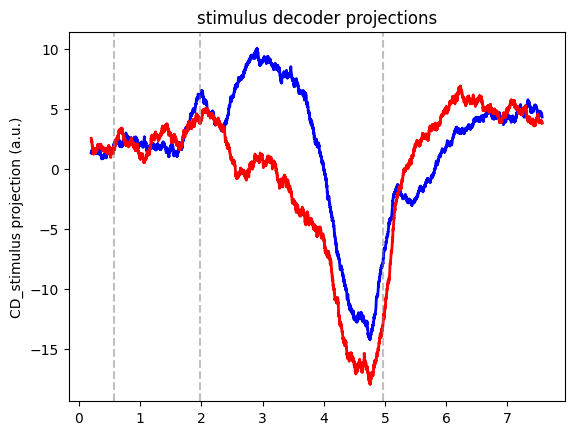

In [10]:
path = r'K:\data\CW69\python\2025_12_19'
path = r'L:\data\CW70\python\2025_11_04'
s1 = Mode(path,  side='L', passive=False, filter_low_perf=False, filter_by_stim=True)
cd_choice, _ = s1.plot_CD(mode_input='stimulus')


In [11]:
s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)

sample_sel = s1.get_epoch_selective((s1.sample, s1.delay), p=0.05)


5 trials removed for stability reasons
only ppyr neurons: 329 --> 268


In [12]:
len(sample_sel)

11

In [13]:
r_n_matrix_righttrials, l_n_matrix_righttrials = [], []
r_n_matrix_lefttrials, l_n_matrix_lefttrials = [], []
for n in sample_sel:
    if n in s1.R_alm_idx:
        # s1.plot_raster_and_PSTH(n)
        r_n_matrix_righttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('r'))]
        r_n_matrix_lefttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('l'))]
    else:
        l_n_matrix_righttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('r'))]
        l_n_matrix_lefttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('l'))]


In [14]:
np.array(l_n_matrix_righttrials).shape

(8, 156)

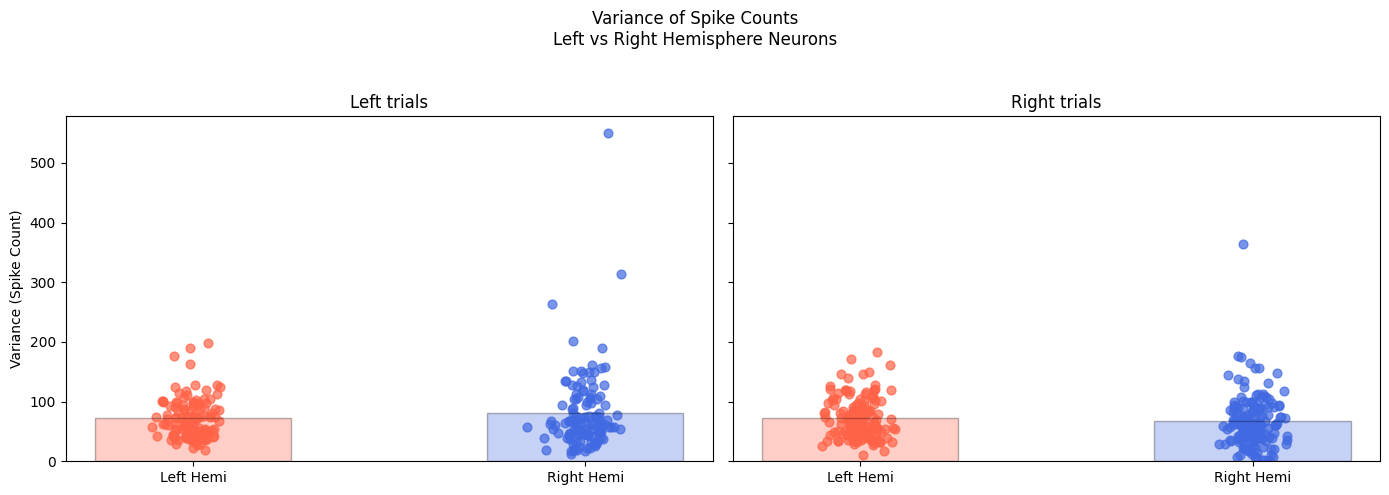

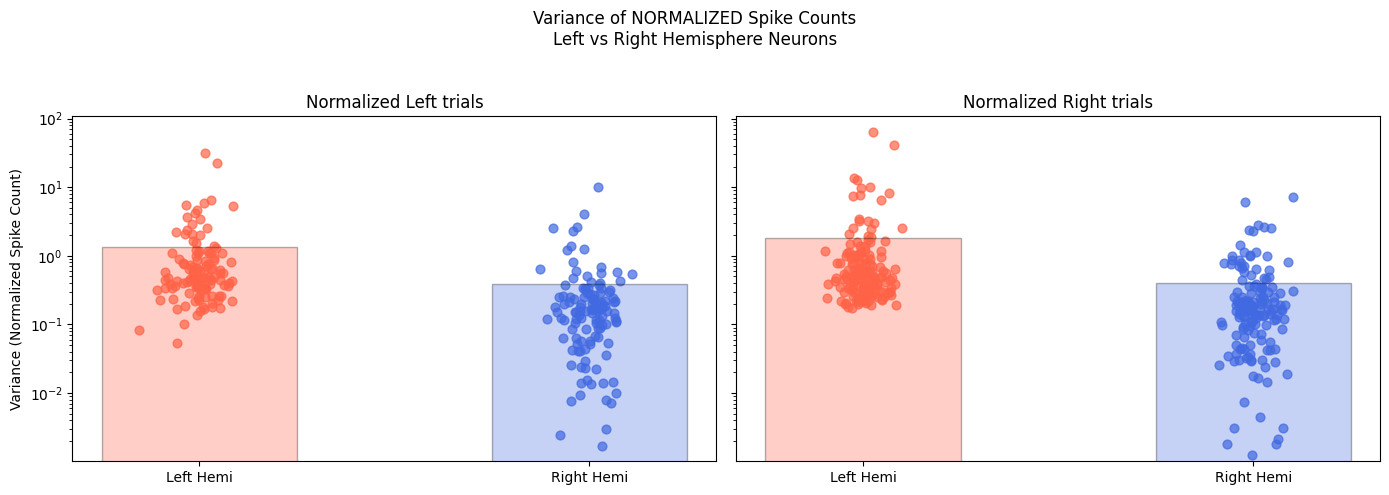

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# --- Raw Variance Plot (original) ---

# Compute variances for right-hemisphere and left-hemisphere neurons for right trials
r_var_right = np.var(r_n_matrix_righttrials, axis=0)
l_var_right = np.var(l_n_matrix_righttrials, axis=0)
mean_r_right = np.mean(r_var_right)
mean_l_right = np.mean(l_var_right)

# And for left trials
r_var_left = np.var(r_n_matrix_lefttrials, axis=0)
l_var_left = np.var(l_n_matrix_lefttrials, axis=0)
mean_r_left = np.mean(r_var_left)
mean_l_left = np.mean(l_var_left)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Plot for right trials (same as before, but on axes[1])
x = np.array([0, 1])
bar_means_right = [mean_l_right, mean_r_right]
labels = ['Left Hemi', 'Right Hemi']
axes[1].scatter(np.full_like(l_var_right, 0, dtype=float)+(np.random.randn(len(l_var_right))*0.04),
              l_var_right, color='tomato', s=40, alpha=0.7, label='_nolegend_')
axes[1].scatter(np.full_like(r_var_right, 1, dtype=float)+(np.random.randn(len(r_var_right))*0.04),
              r_var_right, color='royalblue', s=40, alpha=0.7, label='_nolegend_')
axes[1].bar(x, bar_means_right, color=['tomato', 'royalblue'], alpha=0.3, width=0.5, edgecolor='k')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title('Right trials')

# Plot for left trials (on axes[0])
bar_means_left = [mean_l_left, mean_r_left]
axes[0].scatter(np.full_like(l_var_left, 0, dtype=float)+(np.random.randn(len(l_var_left))*0.04),
              l_var_left, color='tomato', s=40, alpha=0.7, label='_nolegend_')
axes[0].scatter(np.full_like(r_var_left, 1, dtype=float)+(np.random.randn(len(r_var_left))*0.04),
              r_var_left, color='royalblue', s=40, alpha=0.7, label='_nolegend_')
axes[0].bar(x, bar_means_left, color=['tomato', 'royalblue'], alpha=0.3, width=0.5, edgecolor='k')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_title('Left trials')

axes[0].set_ylabel('Variance (Spike Count)')
fig.suptitle('Variance of Spike Counts\nLeft vs Right Hemisphere Neurons')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# --- Normalized (variance of spike counts divided by mean spike count per neuron) ---

def row_normalize(matrix):
    """Normalize each neuron's spike counts (row) by its mean response across all its trials."""
    mat = np.array(matrix)
    mean_per_neuron = np.mean(mat, axis=1, keepdims=True)
    # Avoid division by zero (if a neuron never spikes, we set normalization to NaN)
    with np.errstate(divide='ignore', invalid='ignore'):
        norm_mat = mat / mean_per_neuron
        norm_mat = np.where(np.isnan(norm_mat), 0, norm_mat)  # set nan to 0 for plotting
    return norm_mat

# Normalize matrices
r_n_norm_right = row_normalize(r_n_matrix_righttrials)
l_n_norm_right = row_normalize(l_n_matrix_righttrials)
r_n_norm_left  = row_normalize(r_n_matrix_lefttrials)
l_n_norm_left  = row_normalize(l_n_matrix_lefttrials)

# Variance across trials after normalization
r_var_norm_right = np.var(r_n_norm_right, axis=0)
l_var_norm_right = np.var(l_n_norm_right, axis=0)
mean_r_norm_right = np.mean(r_var_norm_right)
mean_l_norm_right = np.mean(l_var_norm_right)

r_var_norm_left  = np.var(r_n_norm_left, axis=0)
l_var_norm_left  = np.var(l_n_norm_left, axis=0)
mean_r_norm_left = np.mean(r_var_norm_left)
mean_l_norm_left = np.mean(l_var_norm_left)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# --- Set yscale to log for both plots ---
axes[0].set_yscale('log')
axes[1].set_yscale('log')

# Plot for right trials (norm)
bar_means_norm_right = [mean_l_norm_right, mean_r_norm_right]
axes[1].scatter(np.full_like(l_var_norm_right, 0, dtype=float)+(np.random.randn(len(l_var_norm_right))*0.04),
                l_var_norm_right, color='tomato', s=40, alpha=0.7, label='_nolegend_')
axes[1].scatter(np.full_like(r_var_norm_right, 1, dtype=float)+(np.random.randn(len(r_var_norm_right))*0.04),
                r_var_norm_right, color='royalblue', s=40, alpha=0.7, label='_nolegend_')
axes[1].bar(x, bar_means_norm_right, color=['tomato', 'royalblue'], alpha=0.3, width=0.5, edgecolor='k')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title('Normalized Right trials')

# Plot for left trials (norm)
bar_means_norm_left = [mean_l_norm_left, mean_r_norm_left]
axes[0].scatter(np.full_like(l_var_norm_left, 0, dtype=float)+(np.random.randn(len(l_var_norm_left))*0.04),
                l_var_norm_left, color='tomato', s=40, alpha=0.7, label='_nolegend_')
axes[0].scatter(np.full_like(r_var_norm_left, 1, dtype=float)+(np.random.randn(len(r_var_norm_left))*0.04),
                r_var_norm_left, color='royalblue', s=40, alpha=0.7, label='_nolegend_')
axes[0].bar(x, bar_means_norm_left, color=['tomato', 'royalblue'], alpha=0.3, width=0.5, edgecolor='k')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_title('Normalized Left trials')

axes[0].set_ylabel('Variance (Normalized Spike Count)')
fig.suptitle('Variance of NORMALIZED Spike Counts\nLeft vs Right Hemisphere Neurons')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [6]:
l_n_norm_right.shape, r_n_norm_right.shape,  np.vstack([l_n_norm_right, r_n_norm_right]).shape
r_n_norm_right.shape


(7, 125)

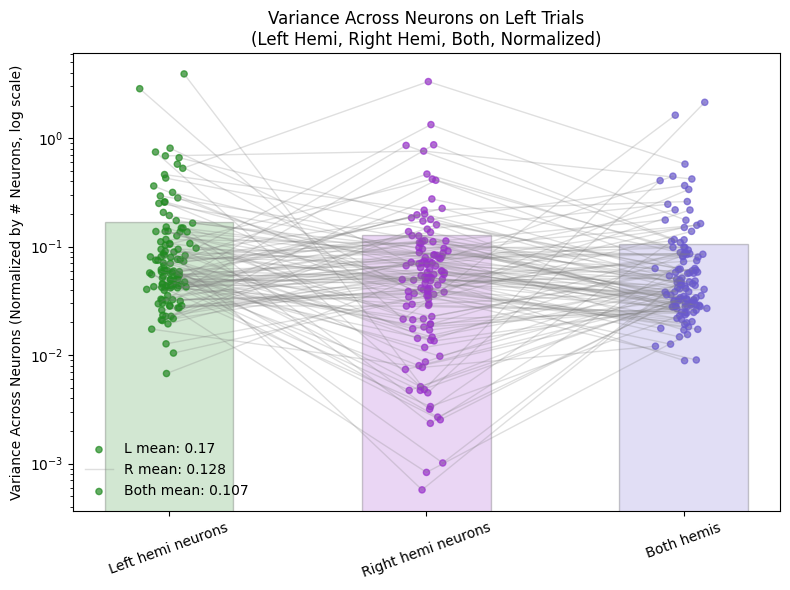

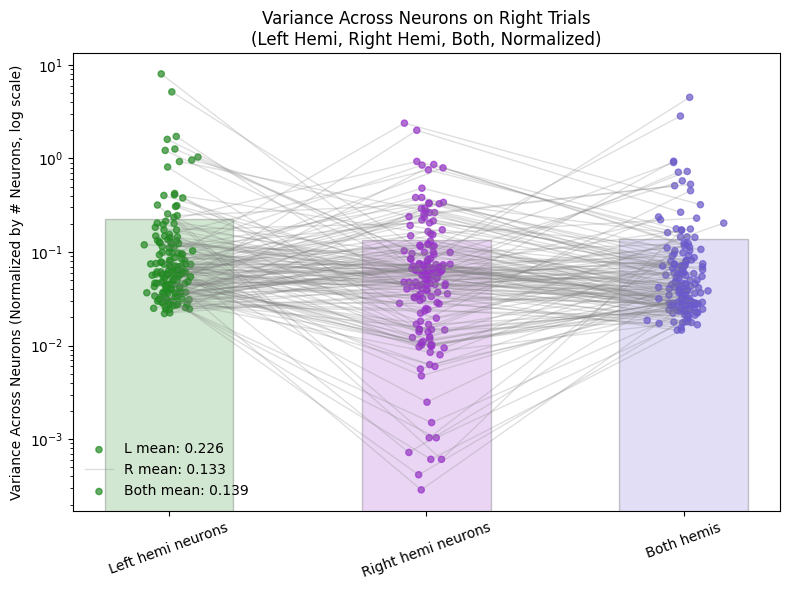

In [16]:

def row_normalize(matrix):
    """Normalize each neuron's spike counts (row) by its mean response across all its trials."""
    mat = np.array(matrix)
    mean_per_neuron = np.mean(mat, axis=1, keepdims=True)
    # Avoid division by zero (if a neuron never spikes, we set normalization to NaN)
    with np.errstate(divide='ignore', invalid='ignore'):
        norm_mat = mat / mean_per_neuron
        norm_mat = np.where(np.isnan(norm_mat), 0, norm_mat)  # set nan to 0 for plotting
    return norm_mat

# Normalize matrices (each neuron's rows are a neuron, cols are trials)
r_n_norm_right = row_normalize(r_n_matrix_righttrials)
l_n_norm_right = row_normalize(l_n_matrix_righttrials)
r_n_norm_left  = row_normalize(r_n_matrix_lefttrials)
l_n_norm_left  = row_normalize(l_n_matrix_lefttrials)

# ----------------- Variance computations -----------------
# --- Variance across neurons (over trials) for both hemispheres and combined ---
# And variance normalization so mean is not artificially high with more neurons.

def variance_across_neurons_over_trials(matrix):
    """Computes, for each trial, the variance *across neurons* for trial t (over all neurons).
    Returns (variances, n_neurons)
    """
    # matrix: shape (neurons, trials)
    var_per_trial = np.var(matrix, axis=0)        # variance across neurons, for each trial
    n_neurons = matrix.shape[0]
    # Normalize variance by number of neurons, as sample variance ~scales with number of neurons
    var_per_trial_norm = var_per_trial / n_neurons if n_neurons > 0 else np.zeros_like(var_per_trial)
    return var_per_trial_norm, n_neurons
# Compute for left trials only, but separate variances for right hemi, left hemi, and both hemispheres.
# Use right-hemisphere neurons: r_n_norm_left (neurons, left trials)
# Use left-hemisphere neurons:  l_n_norm_left (neurons, left trials)

# --- LEFT TRIALS ANALYSIS AND PLOT ---
# Variance for right-hemisphere neurons (on left trials)
var_across_neurons_righthemi_lefttrials, n_r_hemi_L = variance_across_neurons_over_trials(r_n_norm_left)
# Variance for left-hemisphere neurons (on left trials)
var_across_neurons_lefthemi_lefttrials, n_l_hemi_L = variance_across_neurons_over_trials(l_n_norm_left)
# Combined: variance across all neurons (both hemispheres) on left trials
both_hemi_matrix_lefttrials = np.vstack([r_n_norm_left, l_n_norm_left])  # stack (neurons, left trials)
var_across_neurons_bothhemi_lefttrials, n_both_hemi_L = variance_across_neurons_over_trials(both_hemi_matrix_lefttrials)

# Keep only paired trials present in both conditions (all have same number if input matrices have matching trial counts)
n_trials_L = min(
    var_across_neurons_lefthemi_lefttrials.shape[0],
    var_across_neurons_righthemi_lefttrials.shape[0],
    var_across_neurons_bothhemi_lefttrials.shape[0],
)

var_Lh = var_across_neurons_lefthemi_lefttrials[:n_trials_L]
var_Rh = var_across_neurons_righthemi_lefttrials[:n_trials_L]
var_Bh = var_across_neurons_bothhemi_lefttrials[:n_trials_L]

# --- Plotting: Bar plot with scatters and connecting lines for per-trial variance (left trials only) ---

mean_Lh = np.mean(var_Lh)
mean_Rh = np.mean(var_Rh)
mean_Bh = np.mean(var_Bh)

bar_positions_L = np.array([0, 1, 2])
bar_colors_L = ['forestgreen', 'darkorchid', 'slateblue']
labels_L = ['Left hemi neurons', 'Right hemi neurons', 'Both hemis']

fig_L, ax_L = plt.subplots(1, 1, figsize=(8, 6))

# Bar graph: averages
ax_L.bar(bar_positions_L, [mean_Lh, mean_Rh, mean_Bh], color=bar_colors_L, alpha=0.2, width=0.5, edgecolor='k', label='_nolegend_')

# Per trial scatter
rng_L = np.random.default_rng(123)  # reproducibility for left plot; different seed to avoid collisions
for i in range(n_trials_L):
    jitter_L = rng_L.normal(0, 0.04, 3)
    yvals_L = [var_Lh[i], var_Rh[i], var_Bh[i]]
    ax_L.scatter(bar_positions_L + jitter_L, yvals_L, color=bar_colors_L, s=20, alpha=0.7, zorder=2)
    # Connect lines for the same trial
    ax_L.plot(bar_positions_L + jitter_L, yvals_L, color='gray', alpha=0.25, linewidth=1)

ax_L.set_yscale('log')
ax_L.set_xticks(bar_positions_L)
ax_L.set_xticklabels(labels_L, rotation=20)
ax_L.set_ylabel('Variance Across Neurons (Normalized by # Neurons, log scale)')
ax_L.set_title('Variance Across Neurons on Left Trials\n(Left Hemi, Right Hemi, Both, Normalized)')
ax_L.legend([
    f'L mean: {mean_Lh:.3g}',
    f'R mean: {mean_Rh:.3g}',
    f'Both mean: {mean_Bh:.3g}'],
    loc='best', frameon=False)

plt.tight_layout()
plt.show()

# --- RIGHT TRIALS ANALYSIS AND PLOT ---

# Variance for right-hemisphere neurons (on right trials)
var_across_neurons_righthemi_righttrials, n_r_hemi_R = variance_across_neurons_over_trials(r_n_norm_right)
# Variance for left-hemisphere neurons (on right trials)
var_across_neurons_lefthemi_righttrials, n_l_hemi_R = variance_across_neurons_over_trials(l_n_norm_right)
# Combined: variance across all neurons (both hemispheres) on right trials
both_hemi_matrix_righttrials = np.vstack([r_n_norm_right, l_n_norm_right])  # stack (neurons, right trials)
var_across_neurons_bothhemi_righttrials, n_both_hemi_R = variance_across_neurons_over_trials(both_hemi_matrix_righttrials)

n_trials_R = min(
    var_across_neurons_lefthemi_righttrials.shape[0],
    var_across_neurons_righthemi_righttrials.shape[0],
    var_across_neurons_bothhemi_righttrials.shape[0],
)

var_Lh_R = var_across_neurons_lefthemi_righttrials[:n_trials_R]
var_Rh_R = var_across_neurons_righthemi_righttrials[:n_trials_R]
var_Bh_R = var_across_neurons_bothhemi_righttrials[:n_trials_R]

mean_Lh_R = np.mean(var_Lh_R)
mean_Rh_R = np.mean(var_Rh_R)
mean_Bh_R = np.mean(var_Bh_R)

bar_positions_R = np.array([0, 1, 2])
bar_colors_R = ['forestgreen', 'darkorchid', 'slateblue']
labels_R = ['Left hemi neurons', 'Right hemi neurons', 'Both hemis']

fig_R, ax_R = plt.subplots(1, 1, figsize=(8, 6))
ax_R.bar(bar_positions_R, [mean_Lh_R, mean_Rh_R, mean_Bh_R], color=bar_colors_R, alpha=0.2, width=0.5, edgecolor='k', label='_nolegend_')
rng_R = np.random.default_rng(456)
for i in range(n_trials_R):
    jitter_R = rng_R.normal(0, 0.04, 3)
    yvals_R = [var_Lh_R[i], var_Rh_R[i], var_Bh_R[i]]
    ax_R.scatter(bar_positions_R + jitter_R, yvals_R, color=bar_colors_R, s=20, alpha=0.7, zorder=2)
    ax_R.plot(bar_positions_R + jitter_R, yvals_R, color='gray', alpha=0.25, linewidth=1)

ax_R.set_yscale('log')
ax_R.set_xticks(bar_positions_R)
ax_R.set_xticklabels(labels_R, rotation=20)
ax_R.set_ylabel('Variance Across Neurons (Normalized by # Neurons, log scale)')
ax_R.set_title('Variance Across Neurons on Right Trials\n(Left Hemi, Right Hemi, Both, Normalized)')
ax_R.legend([
    f'L mean: {mean_Lh_R:.3g}',
    f'R mean: {mean_Rh_R:.3g}',
    f'Both mean: {mean_Bh_R:.3g}'],
    loc='best', frameon=False)

plt.tight_layout()
plt.show()



### Iterate over different sessions:

16 trials removed for stability reasons
only ppyr neurons: 216 --> 176


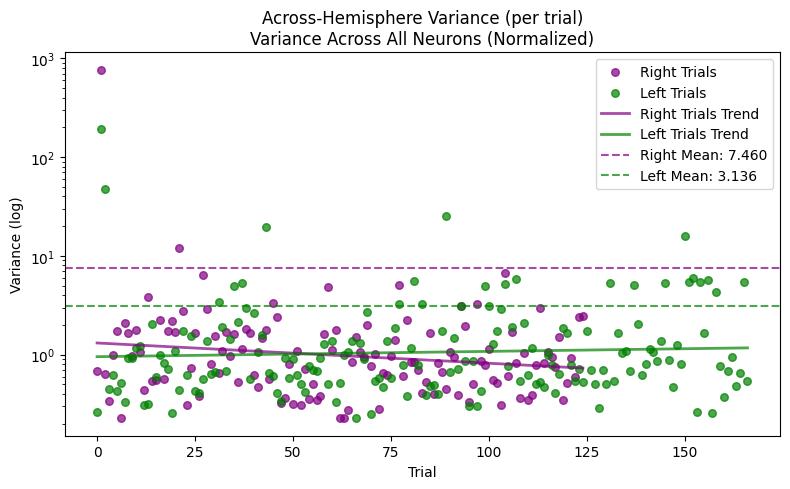

14 trials removed for stability reasons
only ppyr neurons: 305 --> 264


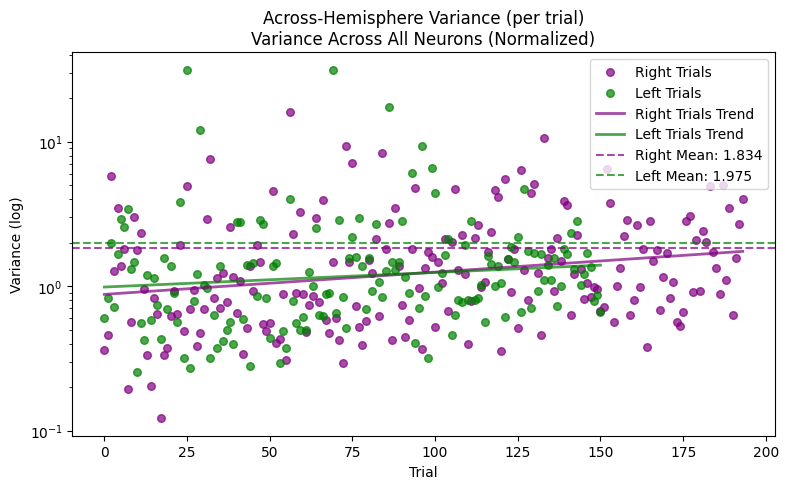

4 trials removed for stability reasons
only ppyr neurons: 422 --> 362


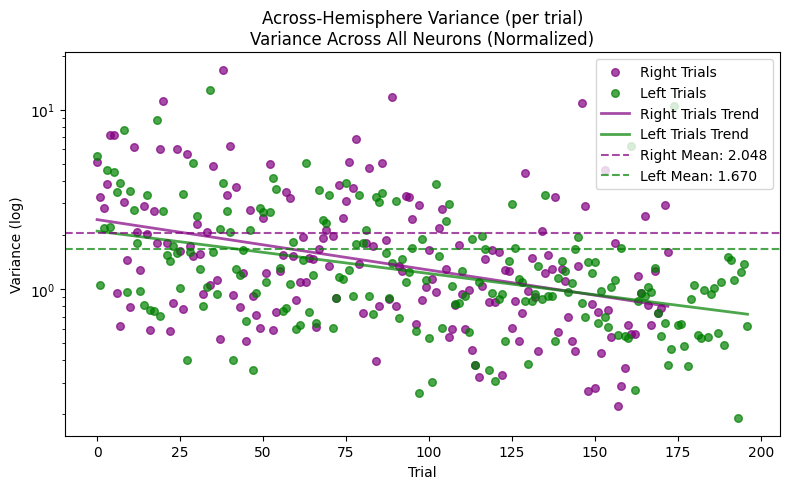

5 trials removed for stability reasons
only ppyr neurons: 328 --> 281


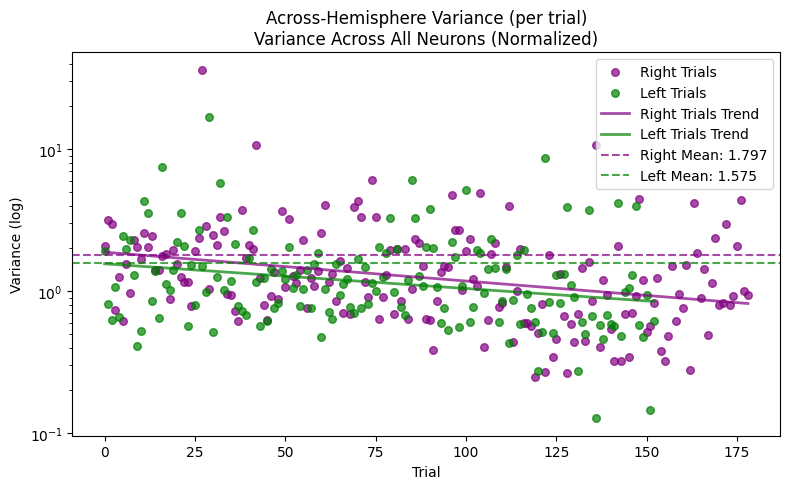

13 trials removed for stability reasons
only ppyr neurons: 178 --> 152


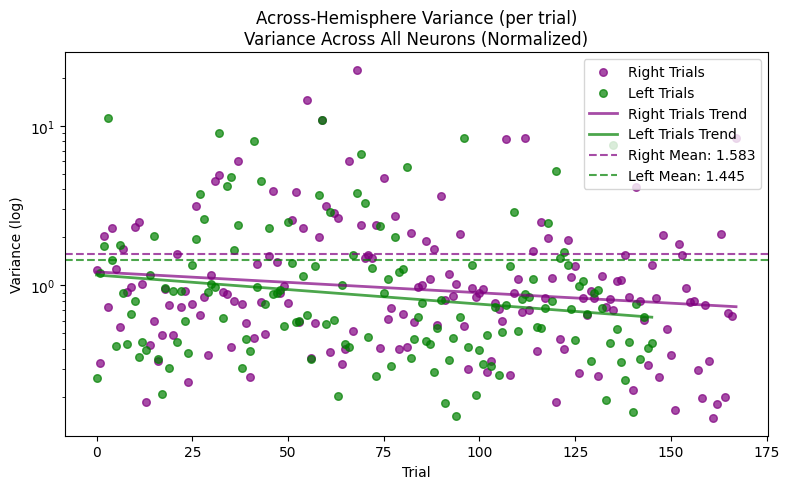

5 trials removed for stability reasons
only ppyr neurons: 329 --> 268


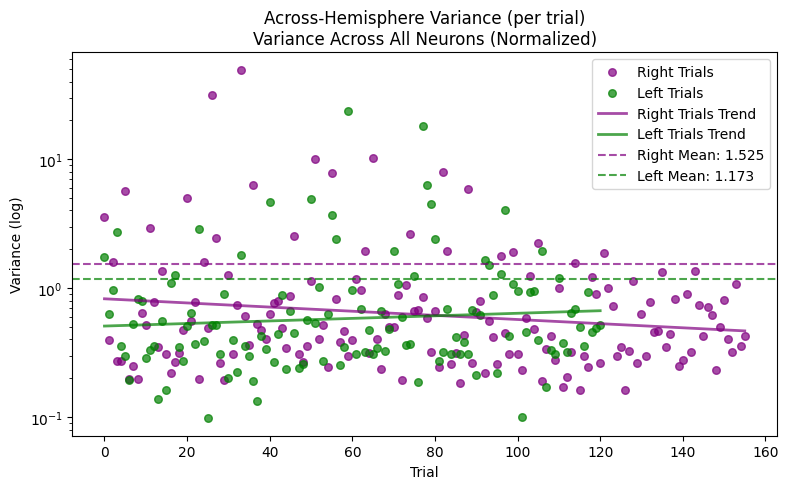

34 trials removed for stability reasons
only ppyr neurons: 407 --> 347


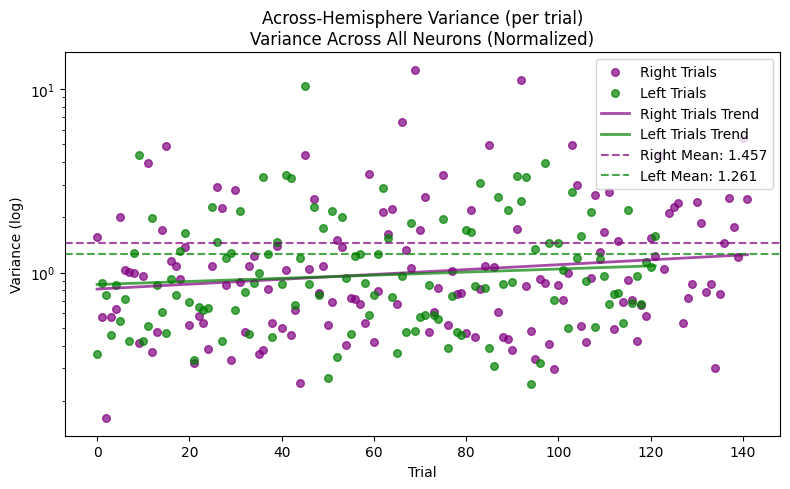

In [66]:
paths = [             
    
            # r'K:\data\CW69\python\2025_12_18',
             r'K:\data\CW69\python\2025_12_19',
 

    
             r'L:\data\CW68\python\2025_12_10',
            r'L:\data\CW68\python\2025_12_12',
           r'L:\data\CW68\python\2025_12_13',
           # r'L:\data\CW68\python\2025_12_14',
           
          
             r'L:\data\CW68\python\2025_12_15',
          
          
            r'L:\data\CW70\python\2025_11_04',
            r'G:\ephys_data\CW65\python\2025_02_25',

            ]


for path in paths:
    s1 = Session(path, passive=False, filter_low_perf=False, filter_by_stim=True)

    sample_sel = s1.get_epoch_selective((s1.sample, s1.delay), p=0.05)

    r_n_matrix_righttrials, l_n_matrix_righttrials = [], []
    r_n_matrix_lefttrials, l_n_matrix_lefttrials = [], []
    for n in sample_sel:
        if n in s1.R_alm_idx:
            # s1.plot_raster_and_PSTH(n)
            r_n_matrix_righttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('r'))]
            r_n_matrix_lefttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('l'))]
        else:
            l_n_matrix_righttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('r'))]
            l_n_matrix_lefttrials += [s1.get_spike_count(n, (s1.sample, s1.delay), s1.trial_type_direction('l'))]


    # Normalize matrices (each neuron's rows are a neuron, cols are trials)
    r_n_norm_right = row_normalize(r_n_matrix_righttrials)
    l_n_norm_right = row_normalize(l_n_matrix_righttrials)
    r_n_norm_left  = row_normalize(r_n_matrix_lefttrials)
    l_n_norm_left  = row_normalize(l_n_matrix_lefttrials)

    # ----------------- Variance computations -----------------

    # Variance across trials, for each neuron (axis=1 means within neuron, across all their trials)
    # We'll treat "within hemisphere" as variance within each neuron in a hemisphere, and "across hemisphere"
    # as variance across neurons (per trial), i.e., within a single trial how variable are the neurons' responses across hemispheres.

    # ---- Within hemisphere variance (per neuron, across trials) ----
    within_r_hemi_var_righttrials = np.var(r_n_norm_right, axis=1)
    within_l_hemi_var_righttrials = np.var(l_n_norm_right, axis=1)
    within_r_hemi_var_lefttrials  = np.var(r_n_norm_left, axis=1)
    within_l_hemi_var_lefttrials  = np.var(l_n_norm_left, axis=1)

    # ---- Across hemisphere variance (per trial, across neurons) ----
    # For this, stack neuron matrices from both hemispheres per trial, then compute variance across neurons for each trial
    across_hemi_matrix_righttrials = np.vstack([l_n_norm_right, r_n_norm_right])  # shape: (n_all_neurons, n_trials)
    across_hemi_matrix_lefttrials  = np.vstack([l_n_norm_left,  r_n_norm_left])

    # Now, per trial variance across ALL neurons (axis=0=across neurons for each trial)
    across_hemi_var_righttrials = np.var(across_hemi_matrix_righttrials, axis=0)
    across_hemi_var_lefttrials  = np.var(across_hemi_matrix_lefttrials,  axis=0)

    # ---- Summary means ----
    mean_within_r_hemi_right  = np.mean(within_r_hemi_var_righttrials)
    mean_within_l_hemi_right  = np.mean(within_l_hemi_var_righttrials)
    mean_within_r_hemi_left   = np.mean(within_r_hemi_var_lefttrials)
    mean_within_l_hemi_left   = np.mean(within_l_hemi_var_lefttrials)

    mean_across_hemi_right    = np.mean(across_hemi_var_righttrials)
    mean_across_hemi_left     = np.mean(across_hemi_var_lefttrials)


    fig2, ax2 = plt.subplots(1, 1, figsize=(8, 5))

    ax2.set_yscale('log')
    x_right = np.arange(len(across_hemi_var_righttrials))
    y_right = across_hemi_var_righttrials
    x_left = np.arange(len(across_hemi_var_lefttrials))
    y_left = across_hemi_var_lefttrials

    # Scatter plots
    ax2.scatter(x_right, y_right, color='purple', s=30, alpha=0.7, label='Right Trials')
    ax2.scatter(x_left, y_left, color='green', s=30, alpha=0.7, label='Left Trials')

    # Trend lines: fit in log-space if plotting on log scale
    # Only fit line to points with finite values
    from numpy import isfinite

    # Fit for right trials
    finite_mask_right = isfinite(y_right) & (y_right > 0)
    if np.any(finite_mask_right):
        log_y_right = np.log10(y_right[finite_mask_right])
        fit_right = np.polyfit(x_right[finite_mask_right], log_y_right, 1)
        poly_right = np.poly1d(fit_right)
        ax2.plot(x_right, 10**poly_right(x_right), color='purple', linestyle='-', linewidth=2, alpha=0.7, label='Right Trials Trend')

    # Fit for left trials
    finite_mask_left = isfinite(y_left) & (y_left > 0)
    if np.any(finite_mask_left):
        log_y_left = np.log10(y_left[finite_mask_left])
        fit_left = np.polyfit(x_left[finite_mask_left], log_y_left, 1)
        poly_left = np.poly1d(fit_left)
        ax2.plot(x_left, 10**poly_left(x_left), color='green', linestyle='-', linewidth=2, alpha=0.7, label='Left Trials Trend')

    # Mean lines
    ax2.axhline(mean_across_hemi_right, color='purple', linestyle='--', alpha=0.7,
                label=f'Right Mean: {mean_across_hemi_right:.3f}')
    ax2.axhline(mean_across_hemi_left, color='green', linestyle='--', alpha=0.7,
                label=f'Left Mean: {mean_across_hemi_left:.3f}')

    ax2.set_title('Across-Hemisphere Variance (per trial)\nVariance Across All Neurons (Normalized)')
    ax2.set_ylabel('Variance (log)')
    ax2.set_xlabel('Trial')
    ax2.legend()
    plt.tight_layout()
    plt.show()

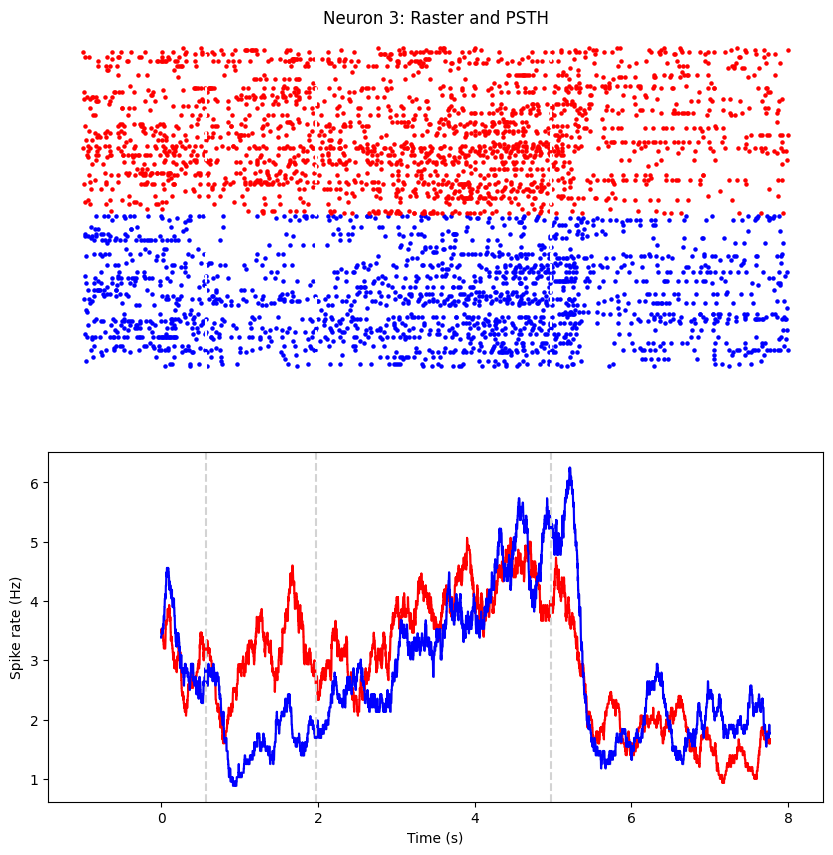

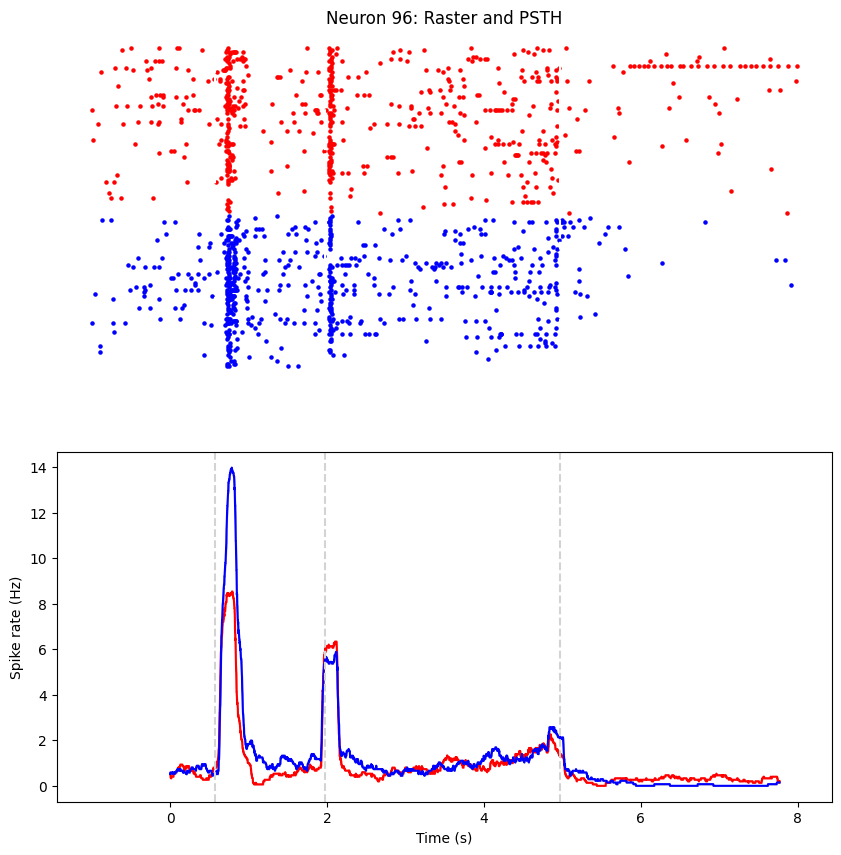

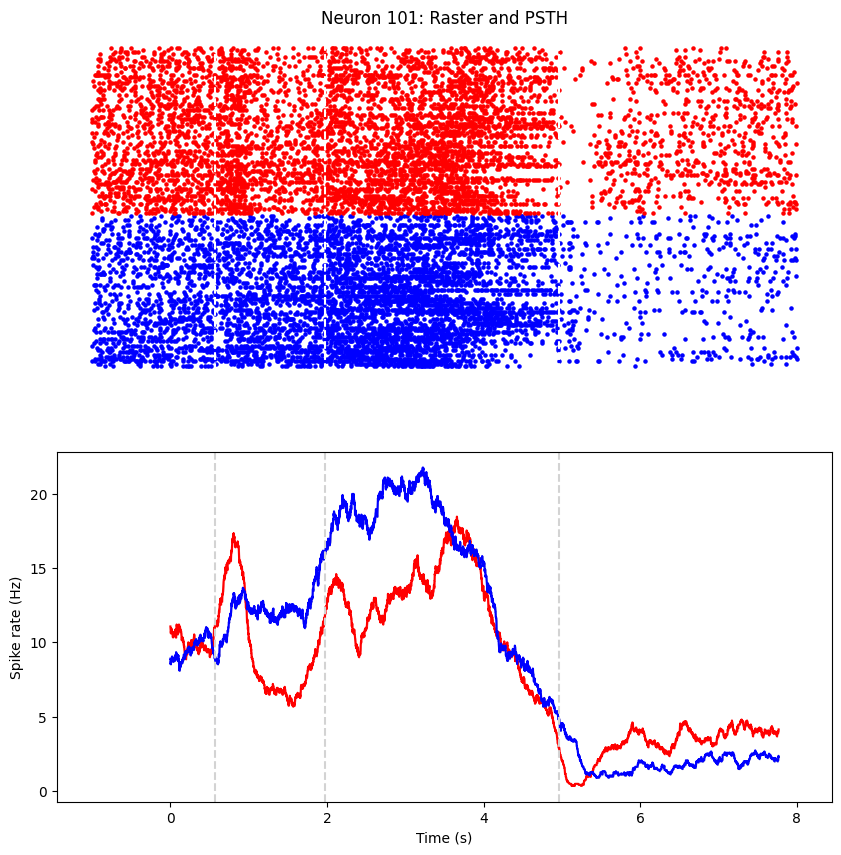

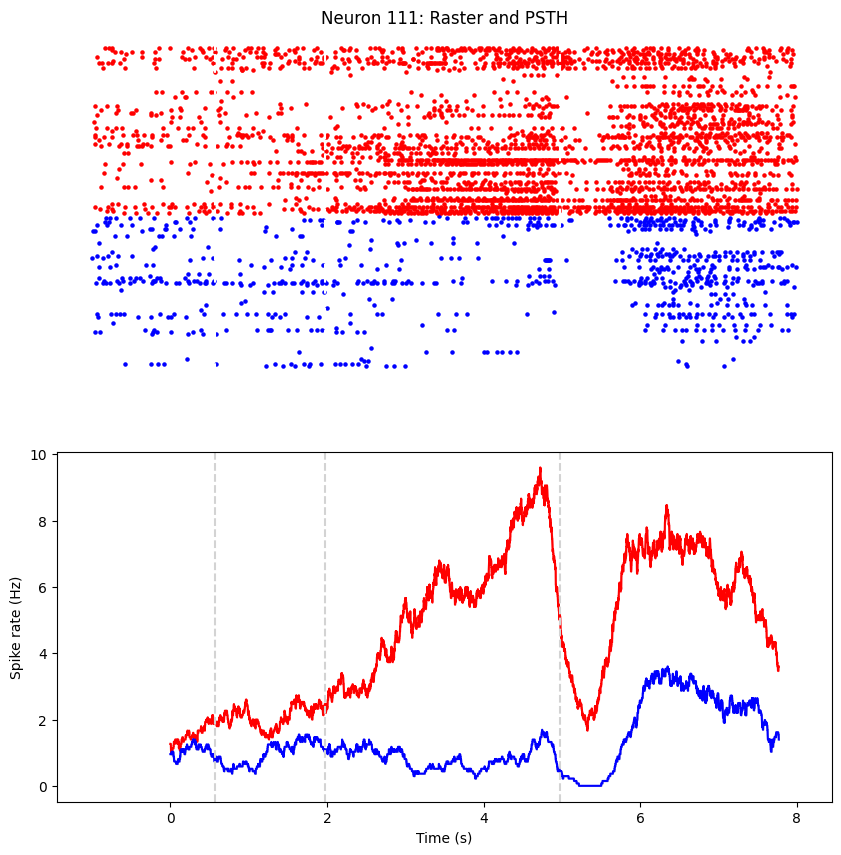

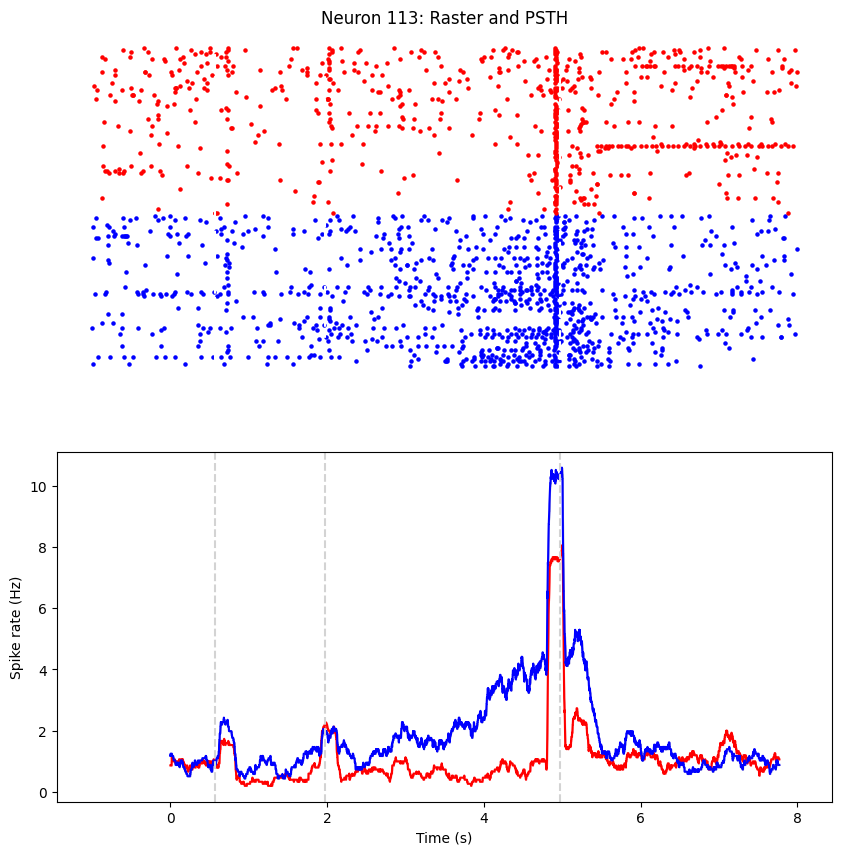

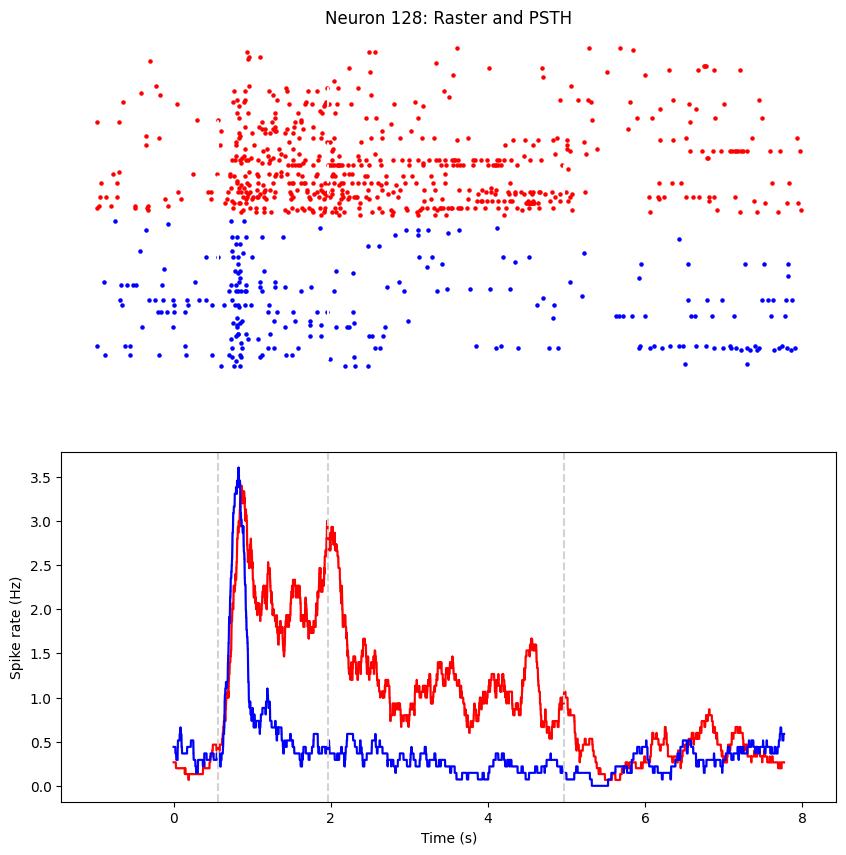

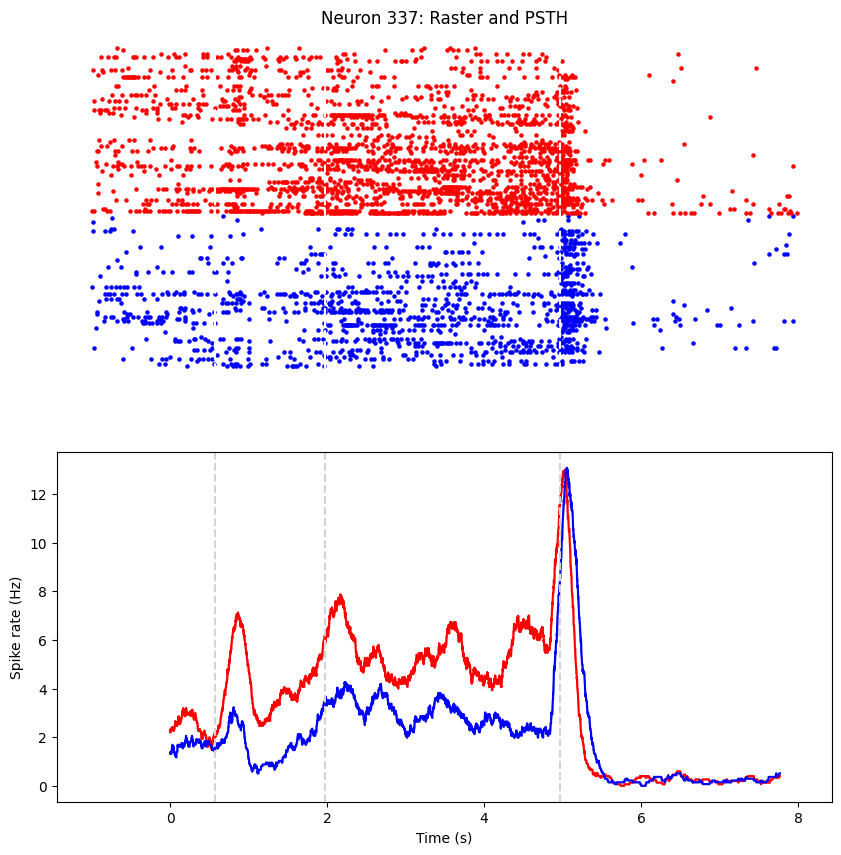

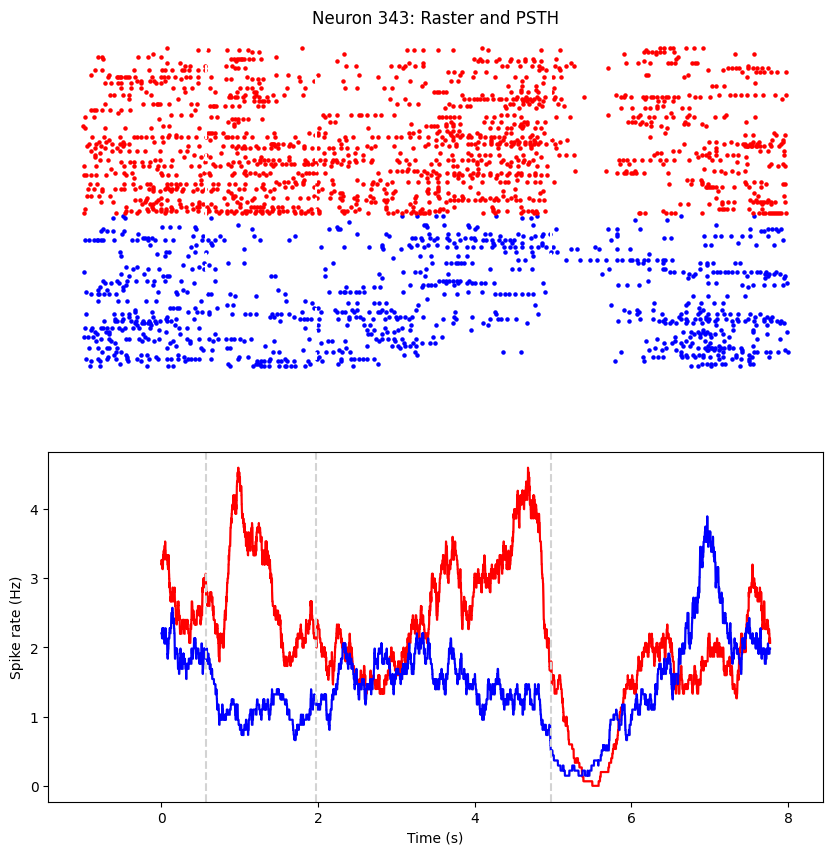

In [25]:
for n in sample_sel:
    s1.plot_raster_and_PSTH(n)